**Задание 2.3.4 Pandas**

Брит Анна

**В домашнем задании 7 (к теме 2.2.5)** у вас была задача:

• Сформулируйте любую интересующую вас практическую задачу и на ее основе по данным dvdrental создайте
запрос, отвечающий следующим требованиям:

• Хотя бы два JOIN

• Хотя бы одно использование GROUP BY

• Хотя бы один CASE

• Хотя бы один WHERE

• Хотя бы одна оконная функция

Ссылка на GitHub:
[Задание 2.2.5](https://github.com/annaabrit-lab/ai-arhitector-innopolis-2026_Brit-Anna/commit/72f3678b6a5b843add3d862616e38f9a7d0f1ac7)

 Скачайте нужные таблицы из базы dvdrental в формате xlsx или csv и сделайте те же самые расчеты с помощью
инструментария Pandas **Текст, выделенный полужирным шрифтом**


**Pandas** — это популярная библиотека с открытым исходным кодом на языке Python для обработки, очистки и анализа табличных данных и временных рядов.

Название происходит от эконометрического термина **panel data** («панельные данные»).


**Основные структуры данных**

• Series — одномерный массив с метками (индексами).

-- Объекты film, inventory, rental, а также итоговые df и result — это всё DataFrame (двумерные таблицы).

• DataFrame — двумерная таблица со строками и столбцами, где каждый столбец является объектом Series.

-- Обращение к отдельным столбцам DataFrame. Например, *df['return_date']* или *df['is_overdue']* — это Series (одномерные массивы).

**Примеры использования**

• Загрузка и сохранение данных: чтение и запись файлов **в форматах CSV**, Excel, JSON, SQL, Parquet и других.

-- *pd.read_csv('film.csv')* и т.д. для загрузки данных

• Очистка и подготовка: удаление или заполнение пропусков, **фильтрация, сортировка и преобразование столбцов**.

-- Преобразование столбцов: меняли типы данных с помощью *pd.to_datetime()* (перевод дат в нужный формат) и *pd.to_timedelta()* (перевод срока аренды в дни).

-- Фильтрация: использовали *df[df['return_date'].notnull()]* (аналог WHERE в SQL).

-- Сортировка: В конце каждого скрипта использовали *.sort_values()* (аналог ORDER BY).

• Аналитика и агрегация: группировка данных (**groupby**), расчёт сводных таблиц (pivot_table) и объединение таблиц (**merge**, concat).

-- использовали группировку для подсчета количества прокатов и просрочек по каждому фильму и по каждой категории задержки.

-- использовали *pd.merge()* дважды в каждом скрипте, чтобы соединить film, inventory и rental (аналог JOIN).

• Подготовка к ML и визуализация: предобработка признаков для моделей машинного обучения и построение базовых графиков (часто вместе с **NumPy** и Matplotlib)

-- функция *np.where()* (которая заменила вам CASE WHEN из SQL)

## 1. Добавим файлы и загрузим данные

In [ ]:
from google.colab import files

# Откроется окно выбора файлов. Выберите сразу все три файла (зажмите Ctrl)
uploaded = files.upload()

# После загрузки вы увидите сообщение с именами загруженных файлов

Saving film.csv to film.csv
Saving inventory.csv to inventory.csv
Saving rental.csv to rental.csv


In [ ]:
import pandas as pd
import numpy as np

# 1. Загрузка данных
try:
    film = pd.read_csv('film.csv') # Загрузка и сохранение данных: чтение и запись файлов в форматах CSV
    inventory = pd.read_csv('inventory.csv')
    rental = pd.read_csv('rental.csv')
    print("✅ Все файлы успешно загружены!")
except FileNotFoundError as e:
    print(f"❌ Ошибка: {e}. Проверьте, что файлы загружены в левую панель (папка 📁).")

# Проверим, что в таблицах есть нужные колонки
print("\nКолонки в film:", film.columns.tolist())
print("Колонки в rental:", rental.columns.tolist())
print("Колонки в inventory:", inventory.columns.tolist())

✅ Все файлы успешно загружены!

Колонки в film: ['film_id', 'title', 'rental_duration']
Колонки в rental: ['inventory_id', 'rental_date', 'return_date']
Колонки в inventory: ['inventory_id', 'film_id']


## 2. ЗАДАЧА. Найти фильмы, которые чаще всего отдают с задержкой и показать их рейтинг

In [ ]:


# Убедимся, что колонки с датами имеют правильный формат
#  Python по умолчанию читает даты из CSV просто как текст (строки).
# Функция pd.to_datetime превращает текст в специальный формат "дата и время". Это нужно,
# чтобы потом можно было вычитать одну дату из другой и считать дни.
rental['rental_date'] = pd.to_datetime(rental['rental_date'])
rental['return_date'] = pd.to_datetime(rental['return_date'])

# 1. JOIN
df = pd.merge(
    film[['film_id', 'title', 'rental_duration']],
    inventory[['film_id', 'inventory_id']],
              on='film_id', how='inner')

# УБИРАЕМ 'rental_id' ИЗ СПИСКА КОЛОНОК
df = pd.merge(df,
              rental[['inventory_id', 'rental_date', 'return_date']],
              on='inventory_id', how='inner')

# 2. WHERE
df = df[df['return_date'].notnull()].copy()

# 3. Вычисление дедлайна и флага просрочки
df['deadline'] = df['rental_date'] + pd.to_timedelta(df['rental_duration'], unit='D')
df['is_overdue'] = np.where(df['return_date'] > df['deadline'], 1, 0)

# 4. GROUP BY
result = df.groupby(['film_id', 'title', 'rental_duration']).agg(
    # ВМЕСТО count('rental_id') ИСПОЛЬЗУЕМ size (считает количество строк)
    total_rentals=('inventory_id', 'size'),
    overdue_rentals=('is_overdue', 'sum')
).reset_index()

# 5. RANK
result['overdue_ratio'] = result['overdue_rentals'] / result['total_rentals']
result['overdue_rank'] = result['overdue_ratio'].rank(method='min', ascending=False).astype(int)

# 6. Сортировка
result = result.sort_values(by='overdue_rank')

print(result[['title', 'total_rentals', 'overdue_rentals', 'overdue_rank']].head(10))

                    title  total_rentals  overdue_rentals  overdue_rank
716           Run Pacific             10               10             1
673           Pure Runner             15               14             2
626       Panky Submarine             15               14             2
624     Pajama Jawbreaker             14               13             4
841      Telegraph Voyage             27               25             5
201        Day Unfaithful             13               12             6
652  Pittsburgh Hunchback             12               11             7
289        Feathers Metal             11               10             8
4             African Egg             11               10             8
5            Agent Truman             21               19            10


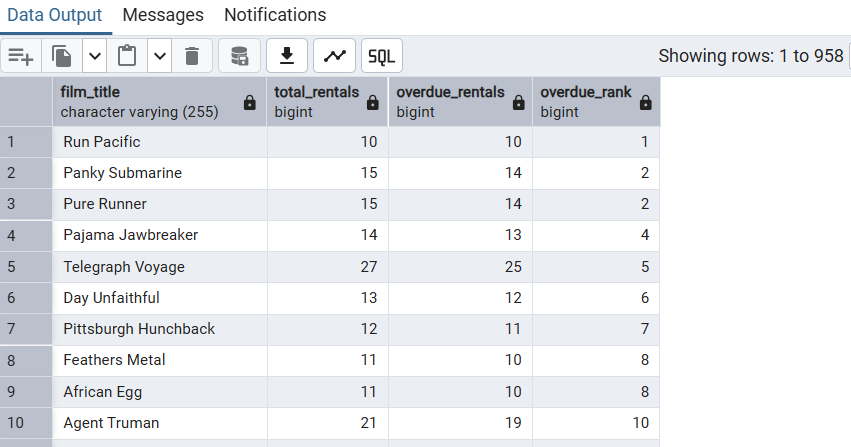

## 3. Проверим гипотезу о зависимости задержки возврата дисков в зависимости от сроков аренды

In [ ]:
# Фильтруем фильмы, у которых есть хотя бы одна просрочка (overdue_rentals > 0)
# И считаем их количество
films_with_overdue = result[result['overdue_rentals'] > 0].shape[0]

# Общее количество фильмов в выборке (для контекста)
total_films_in_result = result.shape[0]

print(f"Всего фильмов в выборке: {total_films_in_result}")
print(f"Из них фильмов с просрочкой (хотя бы 1 раз): {films_with_overdue}")

Всего фильмов в выборке: 958
Из них фильмов с просрочкой (хотя бы 1 раз): 952


Выводы

-- 958 фильмов показано, что соответствует выводам по предыдущей задаче по SQL (2.2.4), о том, что 42 фильма отсутсвуют на складе.

-- из 958 с задержкой хотя бы 1 раз задерживали 952 фильма, т.е клиенты достаточно часто задерживают фильмы.

-- получается просрочка аренды - это не исключение, а норма.

-- возможно стоит задуматься об изменениях в условии аренды, автоматической рассылки напоминайний и т.д.


В pgAdmin можно посмотреть все строки, было удобнее, то, что посчитано отдельно выше (чтобы сделать выводы 1 и 2) - посмотрела в таблице "глазами"

Далее

-- можно посомтреть по каким причинам происходит задержка.

-- например, посмотрим зависимость просрочек от срока аренды (3-7 дней)

In [ ]:
# ---------------------------------------------------------
# 2. JOIN (Соединение таблиц)
# ---------------------------------------------------------
# Соединяем film и inventory
df = pd.merge(film[['film_id', 'rental_duration']],
              inventory[['film_id', 'inventory_id']],
              on='film_id', how='inner')

# Соединяем с rental (используем inventory_id для подсчета строк, если нет rental_id)
df = pd.merge(df,
              rental[['inventory_id', 'rental_date', 'return_date']],
              on='inventory_id', how='inner')

# ---------------------------------------------------------
# 3. WHERE (Фильтрация)
# ---------------------------------------------------------
df = df[df['return_date'].notnull()].copy()

# ---------------------------------------------------------
# 4. Вычисление просрочки
# ---------------------------------------------------------
df['deadline'] = df['rental_date'] + pd.to_timedelta(df['rental_duration'], unit='D')

# Флаг просрочки: 1 если просрочено, 0 если вовремя (CASE)
df['is_overdue'] = np.where(df['return_date'] > df['deadline'], 1, 0)

# ---------------------------------------------------------
# 5. GROUP BY (Группировка по rental_duration)
# ---------------------------------------------------------
result = df.groupby('rental_duration').agg(
    total_rentals=('inventory_id', 'size'),  # COUNT(r.rental_id) - считаем количество строк
    overdue_count=('is_overdue', 'sum')      # SUM(CASE WHEN ...)
).reset_index()

# ---------------------------------------------------------
# 6. Расчет процента и переименование колонок
# ---------------------------------------------------------
# ROUND(SUM(...) / COUNT(...) * 100, 1)
result['overdue_percent'] = (result['overdue_count'] / result['total_rentals'] * 100).round(1)

# Переименовываем колонку, как в SQL
result = result.rename(columns={'rental_duration': 'rental_days'})

# ---------------------------------------------------------
# 7. Сортировка (ORDER BY rental_days)
# ---------------------------------------------------------
result = result.sort_values(by='rental_days')

# Вывод результата
print(result.to_string(index=False))

 rental_days  total_rentals  overdue_count  overdue_percent
           3           3366           2426             72.1
           4           3213           1987             61.8
           5           3132           1572             50.2
           6           3352           1323             39.5
           7           2798            813             29.1


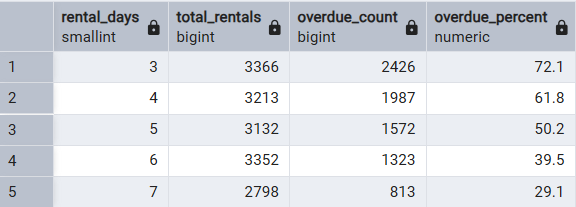

вывод:

-- Когда магазин дает всего 3 дня,
-- клиенты видимо не успевают посмотреть фильм, и 72% из них опаздывают.
-- Когда дают 7 дней — опаздывают в 2.5 раза реже (29%).


Далее можно посмотреть: насколько сильно задерживают

In [ ]:
# ---------------------------------------------------------
# 2. JOIN и WHERE (Аналог CTE overdue_stats)
# ---------------------------------------------------------
df = pd.merge(film[['film_id', 'title', 'rental_duration']],
              inventory[['film_id', 'inventory_id']],
              on='film_id', how='inner')

df = pd.merge(df,
              rental[['inventory_id', 'rental_date', 'return_date']],
              on='inventory_id', how='inner')

# WHERE r.return_date IS NOT NULL
df = df[df['return_date'].notnull()].copy()

# Вычисляем, на сколько дней опоздали (EXTRACT(DAY FROM ...))
df['deadline'] = df['rental_date'] + pd.to_timedelta(df['rental_duration'], unit='D')
df['days_late'] = (df['return_date'] - df['deadline']).dt.days

# ---------------------------------------------------------
# 3. CASE (Аналог CTE categorized_stats)
# ---------------------------------------------------------
# Задаем условия и соответствующие им категории
conditions = [
    (df['days_late'] <= 0),
    (df['days_late'].between(1, 2)),
    (df['days_late'].between(3, 5)),
    (df['days_late'].between(6, 10)),
    (df['days_late'] > 10)
]
choices = ['Вовремя', '1-2 дня', '3-5 дней', '6-10 дней', 'Более 10 дней']

# Создаем колонку late_category
df['late_category'] = np.select(conditions, choices, default='Неизвестно')

# ---------------------------------------------------------
# 4. GROUP BY и ORDER BY (Финальный SELECT)
# ---------------------------------------------------------
# Группируем по категориям и считаем количество (COUNT(*))
result = df.groupby('late_category').size().reset_index(name='rental_count')

# Для правильной сортировки (ORDER BY CASE ...) зададим порядок категорий
category_order = ['Вовремя', '1-2 дня', '3-5 дней', '6-10 дней', 'Более 10 дней']

# Превращаем колонку в категориальный тип с нужным порядком
result['late_category'] = pd.Categorical(result['late_category'], categories=category_order, ordered=True)

# Сортируем по этой колонке (теперь Pandas знает правильный порядок)
result = result.sort_values('late_category')

# Вывод результата
print(result.to_string(index=False))

late_category  rental_count
      Вовремя          9458
      1-2 дня          3482
     3-5 дней          2726
    6-10 дней           195


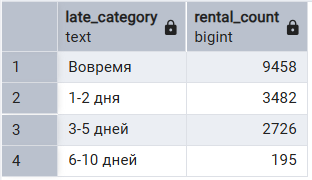

Выводы:
-- Большинство опозданий — это 1-2 дня (3 482 случая)
-- и 3-5 дней (2 726 случаев)
-- большая часть прокатов возвращается вовремя (9 458 случаев)
-- и незначительная часть с задержкой на 6-10 суток (195 случаев)

Далее добавим таблицу с процентом задержек по категориям (количество дней)

In [ ]:
# ---------------------------------------------------------
# 2. JOIN и WHERE (Аналог CTE overdue_stats)
# ---------------------------------------------------------
df = pd.merge(film[['film_id', 'title', 'rental_duration']],
              inventory[['film_id', 'inventory_id']],
              on='film_id', how='inner')

df = pd.merge(df,
              rental[['inventory_id', 'rental_date', 'return_date']],
              on='inventory_id', how='inner')

# WHERE r.return_date IS NOT NULL
df = df[df['return_date'].notnull()].copy()

# Вычисляем, на сколько дней опоздали
df['deadline'] = df['rental_date'] + pd.to_timedelta(df['rental_duration'], unit='D')
df['days_late'] = (df['return_date'] - df['deadline']).dt.days

# ---------------------------------------------------------
# 3. CASE (Аналог CTE categorized_stats)
# ---------------------------------------------------------
conditions = [
    (df['days_late'] <= 0),
    (df['days_late'].between(1, 2)),
    (df['days_late'].between(3, 5)),
    (df['days_late'].between(6, 10)),
    (df['days_late'] > 10)
]
choices = ['Вовремя', '1-2 дня', '3-5 дней', '6-10 дней', 'Более 10 дней']

df['late_category'] = np.select(conditions, choices, default='Неизвестно')

# ---------------------------------------------------------
# 4. GROUP BY и ORDER BY (Финальный SELECT)
# ---------------------------------------------------------
result = df.groupby('late_category').size().reset_index(name='rental_count')

category_order = ['Вовремя', '1-2 дня', '3-5 дней', '6-10 дней', 'Более 10 дней']
result['late_category'] = pd.Categorical(result['late_category'], categories=category_order, ordered=True)

result = result.sort_values('late_category')

# Вывод результата
print(result.to_string(index=False))

late_category  rental_count
      Вовремя          9458
      1-2 дня          3482
     3-5 дней          2726
    6-10 дней           195


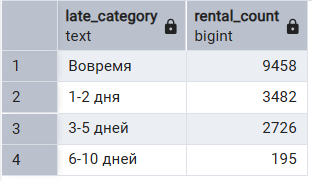

**Общий вывод:**

стоит увеличить срок аренды и ввести напоминанию об истекащем сроке/возможности продления и т.д.